# RateBeer EDA

Exploratory analysis of `ratebeer.json` with a rating-prediction flavor (target: `overall`).

Sections: 1. Load & cache, 2. Data quality audit, 3. Type conversion & normalization

## 1. Load and cache

In [1]:
import ast
import html
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

RAW_PATH = Path("ratebeer.json")
CACHE_PATH = Path("ratebeer.parquet")

In [2]:
def parse_raw(path):
    # file is one python dict literal per line (not valid JSON); skip blank lines and the empty {} record
    with open(path, encoding="utf-8") as f:
        records = [r for r in map(ast.literal_eval, (l for l in f if l.strip())) if r]
    return pd.DataFrame.from_records(records)


def load_raw(raw_path=RAW_PATH, cache_path=CACHE_PATH):
    if cache_path.exists():
        return pd.read_parquet(cache_path)
    df = parse_raw(raw_path)
    df.to_parquet(cache_path, index=False)
    return df


raw = load_raw()
print(f"{len(raw):,} rows x {raw.shape[1]} cols")
raw.head(3)

2,924,163 rows x 13 cols


,beer/name,beer/beerId,beer/brewerId,beer/ABV,beer/style,review/appearance,review/aroma,review/palate,review/taste,review/overall,review/time,review/profileName,review/text
0,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,3/5,6/10,13/20,1157587200,hopdog,"On tap at the Springfield, PA location. Poured..."
1,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,4/5,7/10,13/20,1157241600,TomDecapolis,On tap at the John Harvards in Springfield PA....
2,John Harvards Cristal Pilsner,71716,8481,5,Bohemian Pilsener,4/5,5/10,3/5,6/10,14/20,958694400,PhillyBeer2112,"UPDATED: FEB 19, 2003 Springfield, PA. I've ne..."


## 2. Data quality audit
Runs on the raw string frame, before any conversion.

In [3]:
def missing_table(df):
    s = df.astype("string")
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "null": df.isna().sum(),
        "blank": (s.apply(lambda c: c.str.strip()) == "").sum(),
    })


missing_table(raw)

,dtype,null,blank
beer/name,object,0,0
beer/beerId,object,0,0
beer/brewerId,object,0,0
beer/ABV,object,0,0
beer/style,object,0,0
review/appearance,object,0,0
review/aroma,object,0,0
review/palate,object,0,0
review/taste,object,0,0
review/overall,object,0,0


In [4]:
# score columns should look like "n/d"; check format and which denominators appear
SCORE_COLS = ["review/appearance", "review/aroma", "review/palate", "review/taste", "review/overall"]

def score_audit(df, cols=SCORE_COLS):
    rows = {}
    for c in cols:
        parts = df[c].str.extract(r"^(\d+)/(\d+)$")
        rows[c] = {
            "malformed": int(parts[0].isna().sum() - df[c].isna().sum()),
            "denominators": parts[1].value_counts().to_dict(),
            "max_numerator": pd.to_numeric(parts[0]).max(),
        }
    return pd.DataFrame(rows).T


score_audit(raw)

,malformed,denominators,max_numerator
review/appearance,0,{'5': 2924163},5
review/aroma,0,{'10': 2924163},10
review/palate,0,{'5': 2924163},5
review/taste,0,{'10': 2924163},10
review/overall,0,{'20': 2924163},20


In [5]:
# duplicates: exact repeats, and the same reviewer rating the same beer more than once
print("exact duplicate rows:", raw.duplicated().sum())
print("repeat (beer, reviewer) pairs:", raw.duplicated(["beer/beerId", "review/profileName"]).sum())

exact duplicate rows: 4
repeat (beer, reviewer) pairs: 68931


In [6]:
# ABV: numeric check, missing rate and outliers
abv = pd.to_numeric(raw["beer/ABV"], errors="coerce")
non_numeric = raw["beer/ABV"].notna() & (raw["beer/ABV"].str.strip() != "") & abv.isna()
print("non-numeric ABV strings:", non_numeric.sum())
print(f"ABV missing: {abv.isna().mean():.2%}")
print("ABV == 0:", (abv == 0).sum(), "| ABV > 20:", (abv > 20).sum())
abv.describe()

non-numeric ABV strings: 138637
ABV missing: 4.74%
ABV == 0: 0 | ABV > 20: 1631


count    2.785526e+06
mean     6.640794e+00
std      2.313753e+00
min      1.000000e-02
25%      5.000000e+00
50%      6.000000e+00
75%      8.000000e+00
max      5.770000e+01
Name: beer/ABV, dtype: float64

In [7]:
# html entities in style (e.g. &#40; for "(") and blank review text
entities = raw["beer/style"].str.findall(r"&#?\w+;").explode().value_counts()
print("styles with entities:", raw["beer/style"].str.contains(r"&#?\w+;").sum())
print(entities.to_dict())
print(f"blank review text: {(raw['review/text'].str.strip() == '').mean():.2%}")

styles with entities: 234046
{'&#40;': 234046, '&#41;': 234046}


blank review text: 0.17%


### Audit takeaways
- **Size:** 2,924,163 reviews, 12 fields; no nulls anywhere.
- **Scores:** all well-formed with fixed denominators (appearance/palate /5, aroma/taste /10, overall /20), so the 0-1 normalization is safe.
- **ABV:** 4.74% (138,637) are the placeholder `-`, treated as missing; 1,631 values are above 20% (max 57.7), likely real specialty beers or typos, so worth a look before using ABV as a feature.
- **Style:** `(` and `)` appear as `&#40;` / `&#41;` in 234,046 rows; decoded in section 3.
- **Review text:** 0.17% (5,002) are blank.
- **Duplicates:** 4 exact duplicate rows; 68,931 repeat (beer, reviewer) pairs, which could be re-reviews over time or duplicates, and should be handled before any train/test split.

## 3. Type conversion and normalization
Builds `df` in memory; `raw` is left untouched and nothing is written to disk.

In [8]:
def parse_score(s):
    # numerator and numerator/denominator (0-1 scale); unparseable values become NaN
    p = s.str.extract(r"^(\d+)/(\d+)$").astype("float")
    return p[0], p[0] / p[1]


def decode_style(s):
    # unescape on unique values only; styles are low-cardinality
    mapping = {v: html.unescape(v) for v in s.dropna().unique()}
    return s.map(mapping)


def to_frame(raw):
    df = pd.DataFrame({
        "beer_name": raw["beer/name"],
        "beer_id": raw["beer/beerId"].astype("category"),
        "brewer_id": raw["beer/brewerId"].astype("category"),
        "abv": pd.to_numeric(raw["beer/ABV"], errors="coerce"),
        "style": decode_style(raw["beer/style"]).astype("category"),
        "reviewer": raw["review/profileName"].astype("category"),
        "time": pd.to_datetime(pd.to_numeric(raw["review/time"], errors="coerce"), unit="s"),
        "text": raw["review/text"],
    })
    for name in ["appearance", "aroma", "palate", "taste", "overall"]:
        df[name], df[f"{name}_norm"] = parse_score(raw[f"review/{name}"])
    return df


df = to_frame(raw)
df.dtypes

beer_name                  object
beer_id                  category
brewer_id                category
abv                       float64
style                    category
reviewer                 category
time               datetime64[ns]
text                       object
appearance                float64
appearance_norm           float64
aroma                     float64
aroma_norm                float64
palate                    float64
palate_norm               float64
taste                     float64
taste_norm                float64
overall                   float64
overall_norm              float64
dtype: object

In [9]:
# derived nulls vs raw null/blank counts; a positive diff means malformed values became NaN
source = {"abv": "beer/ABV", "style": "beer/style", "reviewer": "review/profileName", "time": "review/time",
          "appearance": "review/appearance", "aroma": "review/aroma", "palate": "review/palate",
          "taste": "review/taste", "overall": "review/overall"}

def null_check(df, raw, source=source):
    rows = {}
    for d, r in source.items():
        raw_missing = int((raw[r].isna() | (raw[r].astype("string").str.strip() == "")).sum())
        rows[d] = {"raw_missing": raw_missing, "derived_null": int(df[d].isna().sum())}
    out = pd.DataFrame(rows).T
    out["diff"] = out["derived_null"] - out["raw_missing"]
    return out


null_check(df, raw)

,raw_missing,derived_null,diff
abv,0,138637,138637
style,0,0,0
reviewer,0,0,0
time,0,0,0
appearance,0,0,0
aroma,0,0,0
palate,0,0,0
taste,0,0,0
overall,0,0,0


In [10]:
df.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
abv,2785526.0,6.640794,2.313753,0.01,5.0,6.0,8.00,57.7
appearance,2924163.0,3.432027,0.812557,1.00,3.0,3.0,4.00,5.0
appearance_norm,2924163.0,0.686405,0.162511,0.20,0.6,0.6,0.80,1.0
aroma,2924163.0,6.353608,1.639165,1.00,6.0,7.0,7.00,10.0
aroma_norm,2924163.0,0.635361,0.163916,0.10,0.6,0.7,0.70,1.0
palate,2924163.0,3.257236,0.829731,1.00,3.0,3.0,4.00,5.0
palate_norm,2924163.0,0.651447,0.165946,0.20,0.6,0.6,0.80,1.0
taste,2924163.0,6.451929,1.622888,1.00,6.0,7.0,8.00,10.0
taste_norm,2924163.0,0.645193,0.162289,0.10,0.6,0.7,0.80,1.0
overall,2924163.0,13.199696,3.352579,1.00,12.0,14.0,15.00,20.0


## Plotting setup

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")
SCORES = ["appearance", "aroma", "palate", "taste", "overall"]
NORM = [f"{c}_norm" for c in SCORES]


def top_share(counts, q=0.01):
    # share of all reviews that come from the top q fraction of items
    counts = counts.sort_values(ascending=False)
    return counts.head(max(int(len(counts) * q), 1)).sum() / counts.sum()


def plot_long_tail(ax, counts, title):
    ax.hist(counts, bins=np.logspace(0, np.log10(counts.max()), 50))
    ax.set(xscale="log", yscale="log", title=title, xlabel="reviews", ylabel="count")

## 4. Rating distributions and relationships

,mean,std,skew
appearance_norm,0.686405,0.162511,-0.255148
aroma_norm,0.635361,0.163916,-0.787061
palate_norm,0.651447,0.165946,-0.242623
taste_norm,0.645193,0.162289,-0.804271
overall_norm,0.659985,0.167629,-1.029423


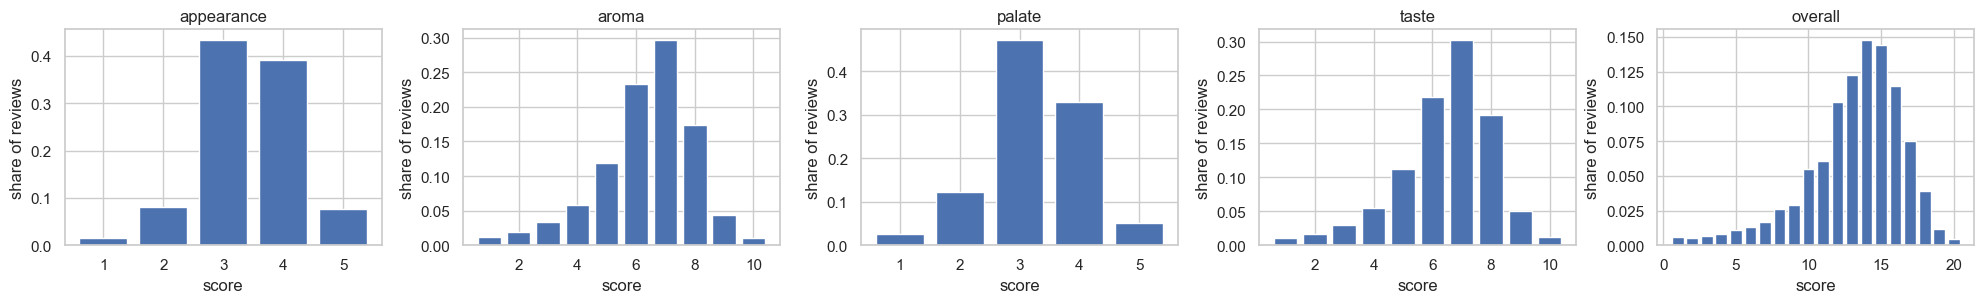

In [12]:
def plot_score_dists(df, cols=SCORES):
    fig, axes = plt.subplots(1, len(cols), figsize=(20, 3.2))
    for ax, c in zip(axes, cols):
        s = df[c].value_counts(normalize=True).sort_index()
        ax.bar(s.index, s.values)
        ax.set(title=c, xlabel="score", ylabel="share of reviews")
    plt.tight_layout()


plot_score_dists(df)
df[NORM].agg(["mean", "std", "skew"]).T

**Takeaways**
- Every score skews high: normalized means are 0.64-0.69, and `overall` has skew -1.03 with its mode at 14-15 out of 20.
- Appearance and palate are coarse (mostly 3-4 out of 5); aroma and taste peak at 7 out of 10. Low scores are rare, so a global-mean baseline will sit near 0.66.

{'taste_norm': 0.876, 'aroma_norm': 0.789, 'palate_norm': 0.701, 'appearance_norm': 0.566}
R^2 of overall from the 4 sub-scores: 0.806


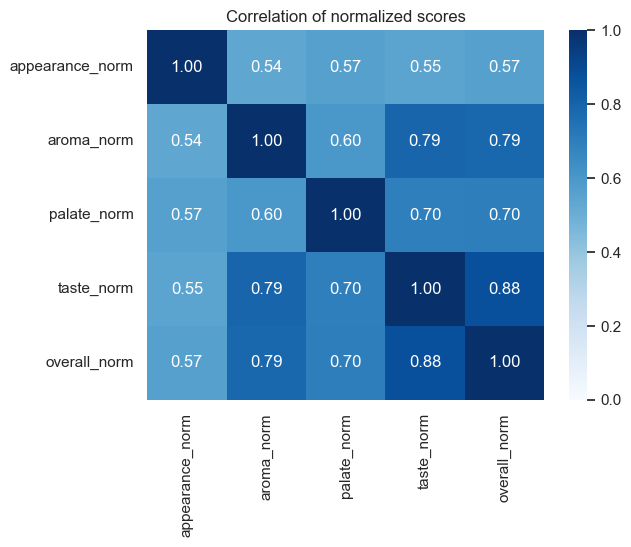

In [13]:
corr = df[NORM].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Correlation of normalized scores")

# multiple R^2 of overall on the 4 sub-scores, from the correlation matrix (no model fit)
x = [c for c in NORM if c != "overall_norm"]
r_xy = corr.loc[x, "overall_norm"].values
r2 = r_xy @ np.linalg.solve(corr.loc[x, x].values, r_xy)
print(corr["overall_norm"].drop("overall_norm").sort_values(ascending=False).round(3).to_dict())
print(f"R^2 of overall from the 4 sub-scores: {r2:.3f}")

**Takeaways**
- `taste` tracks `overall` most closely (r = 0.88), then `aroma` (0.79), `palate` (0.70) and `appearance` (0.57).
- Together the four sub-scores explain 80.6% of the variance in `overall` (R^2 = 0.806). They are written in the same review as `overall`, so they are a leakage risk for any rating-prediction setup and should be excluded or handled separately.

## 5. Beers, brewers, styles and ABV

beers: 110,369 | brewers: 7,547 | styles: 89


beers: median 4 reviews, 51.2% have <5, top 1% hold 34.8% of reviews
brewers: median 36 reviews, top 1% hold 37.8% of reviews


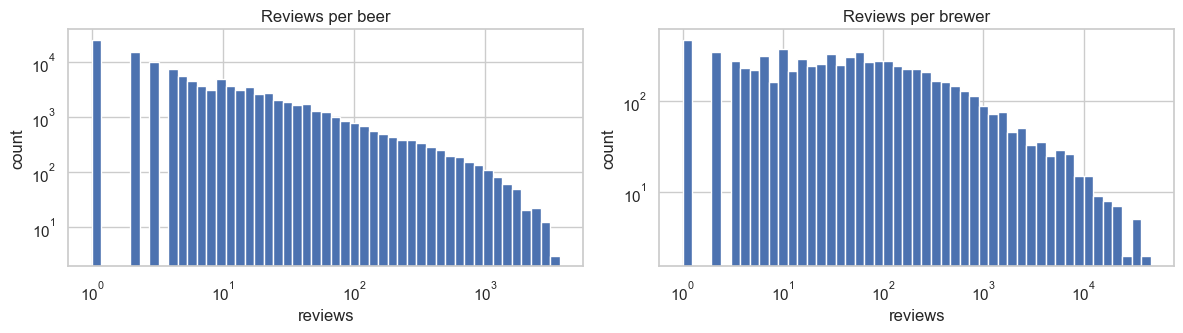

In [14]:
print(f"beers: {df['beer_id'].nunique():,} | brewers: {df['brewer_id'].nunique():,} | styles: {df['style'].nunique():,}")

beer_counts = df["beer_id"].value_counts()
brewer_counts = df["brewer_id"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_long_tail(axes[0], beer_counts, "Reviews per beer")
plot_long_tail(axes[1], brewer_counts, "Reviews per brewer")
plt.tight_layout()

print(f"beers: median {beer_counts.median():.0f} reviews, {(beer_counts < 5).mean():.1%} have <5, top 1% hold {top_share(beer_counts):.1%} of reviews")
print(f"brewers: median {brewer_counts.median():.0f} reviews, top 1% hold {top_share(brewer_counts):.1%} of reviews")

**Takeaways**
- 110,369 beers, 7,547 brewers, 89 styles.
- Both beers and brewers are heavily long-tailed: the median beer has only 4 reviews and 51.2% have fewer than 5, while the top 1% of beers hold 34.8% of all reviews (brewers: median 36, top 1% hold 37.8%).
- Per-beer averages will be noisy for most beers, so any beer-level feature needs smoothing and a cold-start plan.

89 styles, 77 with >=1000 reviews


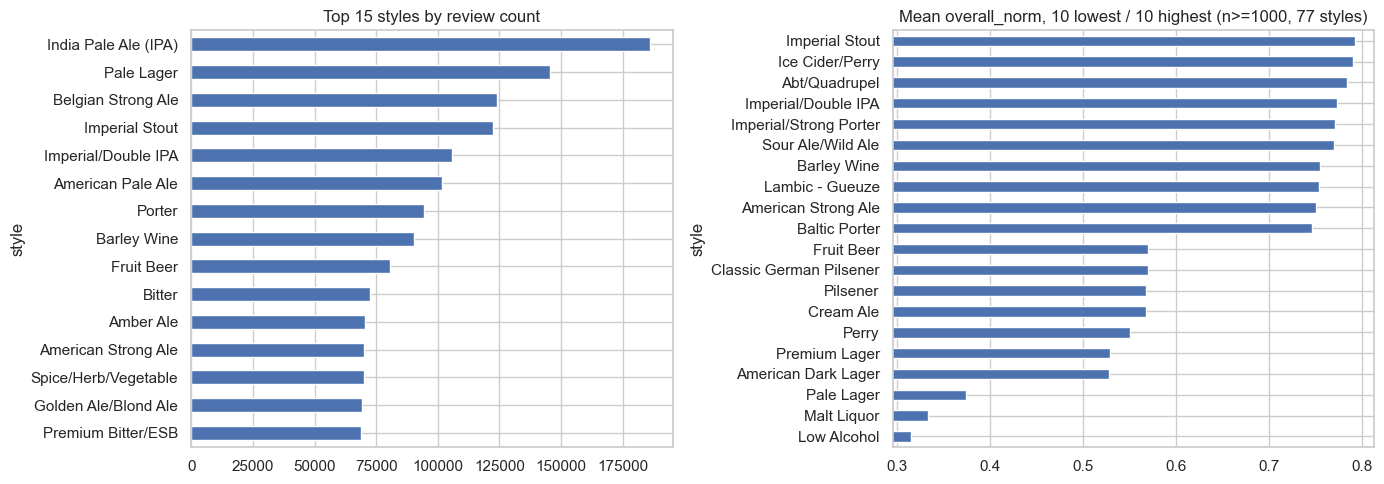

In [15]:
style_stats = df.groupby("style", observed=True).agg(n=("overall_norm", "size"), mean=("overall_norm", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
style_stats["n"].nlargest(15).sort_values().plot.barh(ax=axes[0], title="Top 15 styles by review count")

# mean rating, only for styles with enough reviews to be stable
big = style_stats[style_stats["n"] >= 1000]["mean"].sort_values()
pd.concat([big.head(10), big.tail(10)]).plot.barh(ax=axes[1], title=f"Mean overall_norm, 10 lowest / 10 highest (n>=1000, {len(big)} styles)")
axes[1].set_xlim(big.min() - 0.02, big.max() + 0.02)
plt.tight_layout()
print(f"{len(style_stats)} styles, {len(big)} with >=1000 reviews")

Spearman(abv, overall_norm): 0.471
mean overall_norm, ABV missing vs present: {False: 0.662, True: 0.624}
ABV > 20: 1631


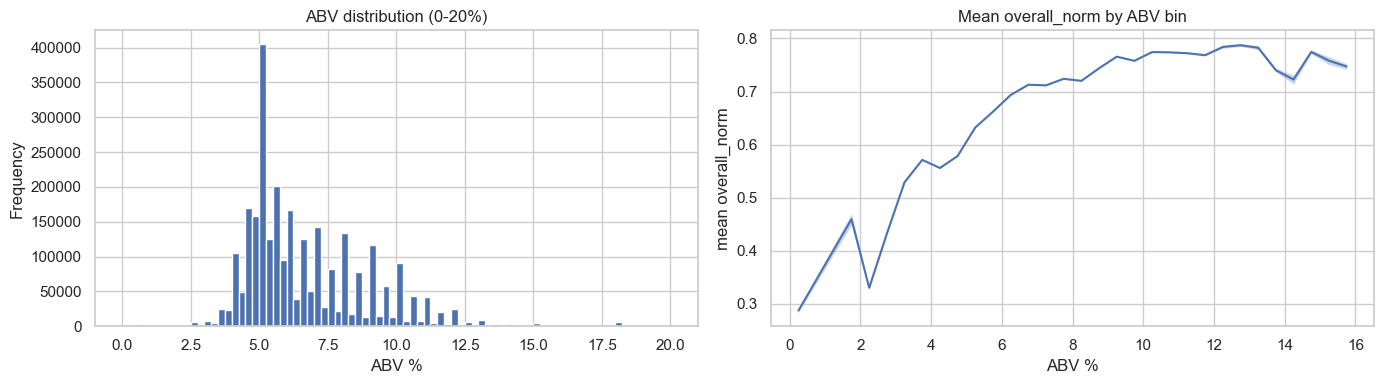

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["abv"].dropna().plot.hist(bins=80, range=(0, 20), ax=axes[0], title="ABV distribution (0-20%)")
axes[0].set_xlabel("ABV %")

# mean overall by ABV bin, 95% CI band; skip thin bins
bins = pd.cut(df["abv"], np.arange(0, 16.5, 0.5))
g = df.groupby(bins, observed=True)["overall_norm"].agg(["mean", "sem", "size"])
g = g[g["size"] >= 500]
mid = g.index.map(lambda i: i.mid).astype(float)
axes[1].plot(mid, g["mean"])
axes[1].fill_between(mid, g["mean"] - 1.96 * g["sem"], g["mean"] + 1.96 * g["sem"], alpha=0.3)
axes[1].set(title="Mean overall_norm by ABV bin", xlabel="ABV %", ylabel="mean overall_norm")
plt.tight_layout()

print("Spearman(abv, overall_norm):", round(df[["abv", "overall_norm"]].corr(method="spearman").iloc[0, 1], 3))
print("mean overall_norm, ABV missing vs present:", df.groupby(df["abv"].isna())["overall_norm"].mean().round(3).to_dict())
print("ABV > 20:", (df["abv"] > 20).sum())

**Takeaways**
- India Pale Ale is the most reviewed style (~185k reviews), followed by Pale Lager and Belgian Strong Ale.
- Style matters a lot: among styles with at least 1,000 reviews, mean `overall_norm` runs from ~0.32 (Low Alcohol) to ~0.79 (Imperial Stout). Strong, rich styles (Imperial Stout, Quadrupel, Imperial IPA, Barley Wine) rate highest; light lagers and malt liquor rate lowest, including the high-volume Pale Lager (~0.37).
- ABV peaks at 5% and spikes at round numbers (whole and half percents), so it is reported coarsely. Rating rises steeply up to ~10% ABV (Spearman 0.47), then plateaus near 0.77-0.79 and dips slightly above 14%. ABV is partly a proxy for style, so the two overlap.
- Beers with a missing ABV rate lower on average (0.624 vs 0.662), so missingness itself may carry signal. 1,631 ABVs exceed 20%.

## 6. Reviewers and time

reviewers: 29,265 | median 3 reviews | top 1% hold 37.0% of reviews
reviewers with 1 review: 31.5% | with >=20: 6,802


std of reviewer means: 0.089 vs std of all reviews: 0.168


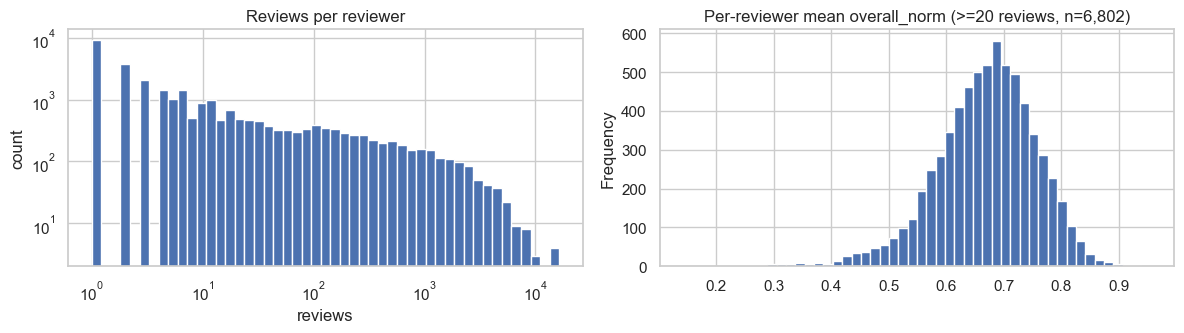

In [17]:
reviewer_counts = df["reviewer"].value_counts()
print(f"reviewers: {len(reviewer_counts):,} | median {reviewer_counts.median():.0f} reviews | top 1% hold {top_share(reviewer_counts):.1%} of reviews")
print(f"reviewers with 1 review: {(reviewer_counts == 1).mean():.1%} | with >=20: {(reviewer_counts >= 20).sum():,}")

rev = df.groupby("reviewer", observed=True)["overall_norm"].agg(["mean", "size"])
active = rev[rev["size"] >= 20]["mean"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_long_tail(axes[0], reviewer_counts, "Reviews per reviewer")
active.plot.hist(bins=50, ax=axes[1], title=f"Per-reviewer mean overall_norm (>=20 reviews, n={len(active):,})")
plt.tight_layout()

print(f"std of reviewer means: {active.std():.3f} vs std of all reviews: {df['overall_norm'].std():.3f}")

**Takeaways**
- 29,265 reviewers; the median has only 3 reviews, 31.5% have a single review, and the top 1% account for 37.0% of all reviews. 6,802 reviewers have 20 or more.
- Reviewers differ in leniency: the standard deviation of per-reviewer mean `overall_norm` (reviewers with >=20 reviews) is 0.089 against 0.168 across all reviews, roughly 28% of the variance. Reviewer identity is likely a strong predictive signal, and also a reason to split by time or reviewer carefully.

time range: 2000-04-12 00:00:00 -> 2012-01-13 00:00:00
reviews before 2000-01-01: 0


,n,mean,share,cum_share
time,,,,
2000,4554,0.653,0.002,0.002
2001,26076,0.620,0.009,0.010
2002,92260,0.632,0.032,0.042
2003,117577,0.639,0.040,0.082
2004,171235,0.644,0.059,0.141
2005,218299,0.643,0.075,0.215
2006,266266,0.651,0.091,0.307
2007,353168,0.656,0.121,0.427
2008,391552,0.661,0.134,0.561


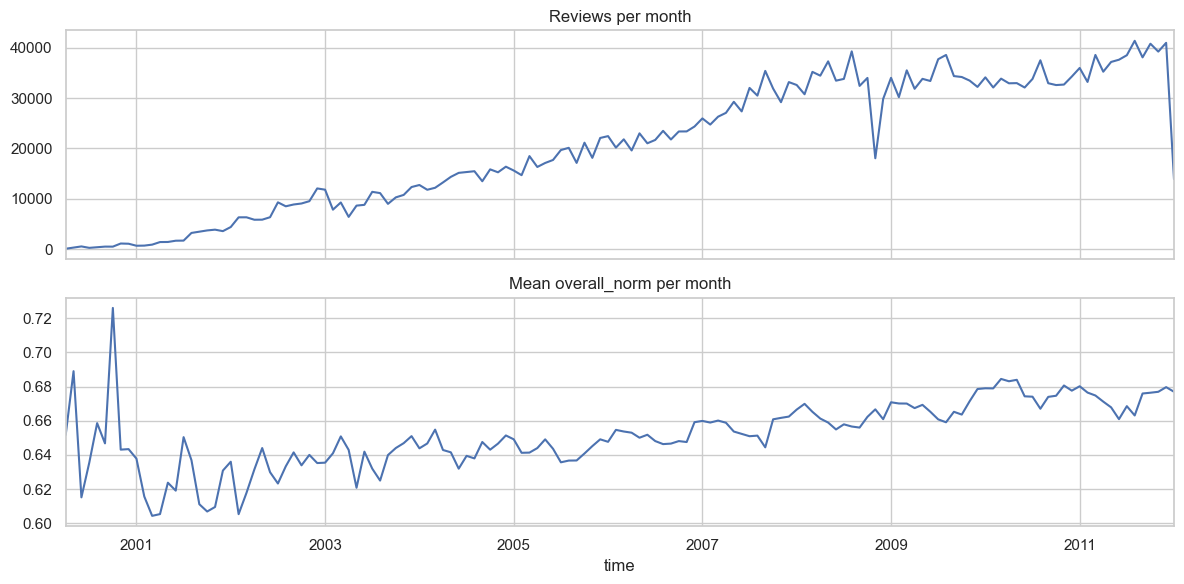

In [18]:
print("time range:", df["time"].min(), "->", df["time"].max())
print("reviews before 2000-01-01:", (df["time"] < "2000-01-01").sum())

monthly = df.groupby(df["time"].dt.to_period("M"))["overall_norm"].agg(["size", "mean"])
monthly.index = monthly.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
monthly["size"].plot(ax=axes[0], title="Reviews per month")
monthly["mean"].plot(ax=axes[1], title="Mean overall_norm per month")
plt.tight_layout()

yearly = df.groupby(df["time"].dt.year)["overall_norm"].agg(n="size", mean="mean")
yearly["share"] = yearly["n"] / yearly["n"].sum()
yearly["cum_share"] = yearly["share"].cumsum()
yearly.round(3)

In [19]:
# time-split check: gaps and where candidate cutoffs fall
full = pd.period_range(df["time"].min(), df["time"].max(), freq="M").to_timestamp()
counts = monthly["size"].reindex(full, fill_value=0)
print("months with 0 reviews:", int((counts == 0).sum()), "| months below 1% of the peak month:", int((counts < 0.01 * counts.max()).sum()))
print("date at 80% / 90% of reviews:", df["time"].quantile([0.8, 0.9]).dt.date.tolist())
print("share of reviews in the last 12 months of data:", round((df["time"] > df["time"].max() - pd.Timedelta(days=365)).mean(), 3))

months with 0 reviews: 0 | months below 1% of the peak month: 4
date at 80% / 90% of reviews: [datetime.date(2010, 9, 17), datetime.date(2011, 5, 30)]
share of reviews in the last 12 months of data: 0.156


**Takeaways**
- Reviews span 2000-04 to 2012-01 and grow steadily from about 1k to about 40k per month. There is one sharp dip around mid-2008 (~18k), and the last month (Jan 2012) is partial. No month is empty.
- Mean `overall_norm` drifts up from ~0.62-0.65 (2001-2005) to ~0.68 (2010-2012); the earliest months are noisy because of small counts.
- For a time-based split, 80% of reviews fall before 2010-09-17 and 90% before 2011-05-30; the last 12 months hold 15.6% of the data.

## 7. Light text EDA

blank reviews: 0.17% | median words: 43 | mean: 53 | p99: 192


Spearman(n_words, overall_norm): 0.203


,mean,size
n_words,,
0,0.638,5002
1-25,0.606,476905
26-50,0.652,1281620
51-100,0.685,922181
101-200,0.712,213258
201-400,0.738,23240
400+,0.766,1957


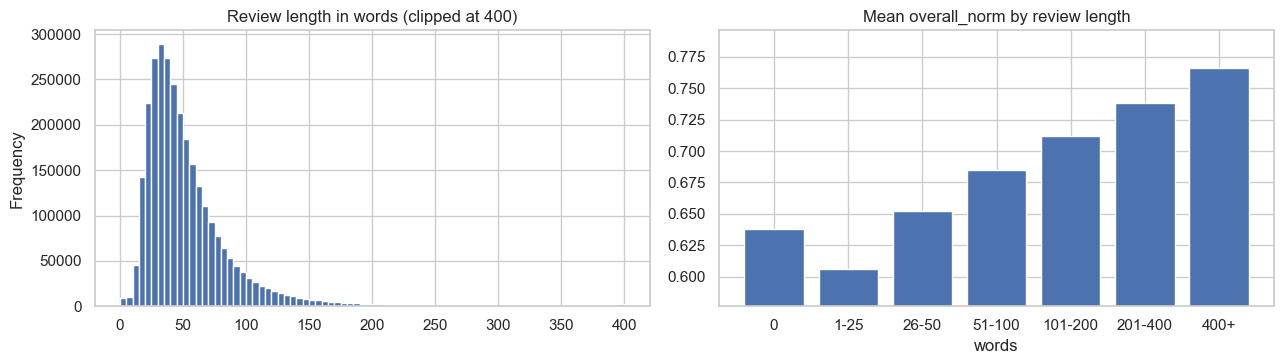

In [20]:
import re
from collections import Counter

df["n_words"] = df["text"].str.count(r"\S+")

print(f"blank reviews: {(df['n_words'] == 0).mean():.2%} | median words: {df['n_words'].median():.0f} | mean: {df['n_words'].mean():.0f} | p99: {df['n_words'].quantile(0.99):.0f}")
print("Spearman(n_words, overall_norm):", round(df[["n_words", "overall_norm"]].corr(method="spearman").iloc[0, 1], 3))

buckets = pd.cut(df["n_words"], [-1, 0, 25, 50, 100, 200, 400, np.inf], labels=["0", "1-25", "26-50", "51-100", "101-200", "201-400", "400+"])
by_len = df.groupby(buckets, observed=True)["overall_norm"].agg(["mean", "size"])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
df["n_words"].clip(upper=400).plot.hist(bins=80, ax=axes[0], title="Review length in words (clipped at 400)")
axes[1].bar(by_len.index.astype(str), by_len["mean"])
axes[1].set(title="Mean overall_norm by review length", xlabel="words", ylim=(by_len["mean"].min() - 0.03, by_len["mean"].max() + 0.03))
plt.tight_layout()
by_len.round(3)

**Takeaways**
- Reviews are short: median 43 words, mean 53, 99th percentile 192; only 0.17% (5,002) are blank (mean `overall_norm` 0.638).
- Longer reviews rate higher (Spearman 0.20): mean `overall_norm` rises from 0.606 for 1-25 words to 0.738 for 201-400 and 0.766 for 400+. Most reviews are under 100 words, so length is a usable but modest signal.

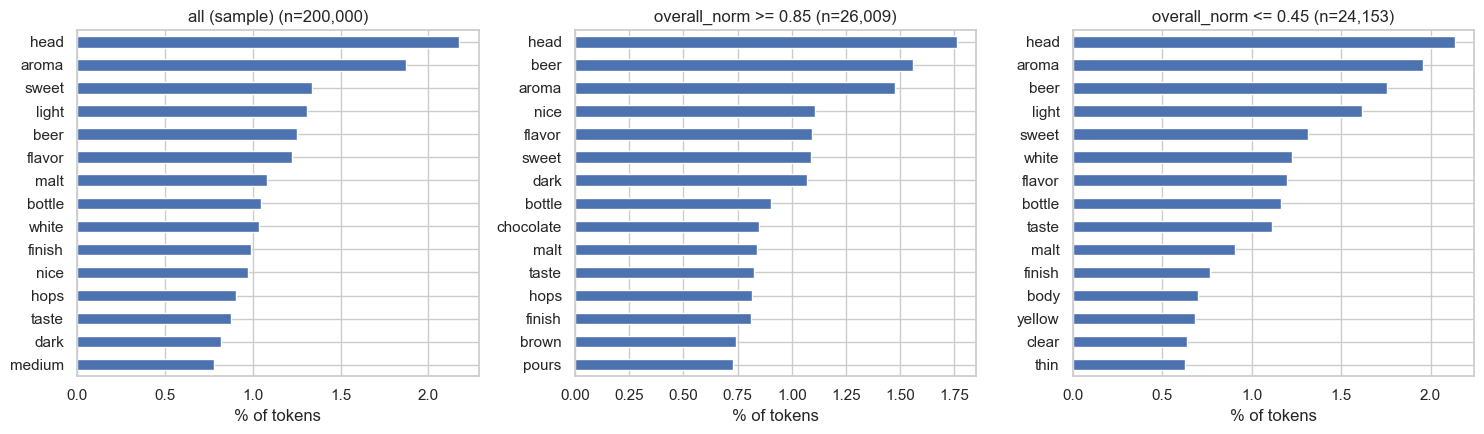

In [21]:
STOP = set("""the and a an of to in is it with this that for was on as but are be at not or by have has had from its very some
more than there like little good just can out up were all one would about into too also while their them then which what when
over after me my you your we they he she his her him our so if no do did does been being these those other any only much quite
really get got well here where who how why""".split())


def top_words(texts, n=15):
    # relative frequency (%) among non-stopword tokens
    counts = Counter(w for t in texts for w in re.findall(r"[a-z']{3,}", t.lower()) if w not in STOP)
    total = sum(counts.values())
    return pd.Series({w: 100 * c / total for w, c in counts.most_common(n)})


# 200k random reviews: counting tokens over all 2.9M in pure python is too slow
sample = df.sample(200_000, random_state=0)
groups = {
    "all (sample)": sample["text"],
    "overall_norm >= 0.85": sample.loc[sample["overall_norm"] >= 0.85, "text"],
    "overall_norm <= 0.45": sample.loc[sample["overall_norm"] <= 0.45, "text"],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, texts) in zip(axes, groups.items()):
    top_words(texts).sort_values().plot.barh(ax=ax, title=f"{name} (n={len(texts):,})")
    ax.set_xlabel("% of tokens")
plt.tight_layout()

**Takeaways**
- Top words are descriptive vocabulary (head, aroma, sweet, light, beer, flavor, malt) and are almost the same across rating groups.
- High-rated reviews over-index on "nice", "dark", "chocolate" and "brown"; low-rated ones on "white", "yellow", "clear" and "thin", which describe pale, watery beers. This mostly echoes the style effect from section 5 rather than sentiment words (word counts are from a 200k-review sample).

## 8. Prediction-oriented summary

In [22]:
# time-based holdout from section 6; baselines are train-set means scored on the later 20%
cutoff = df["time"].quantile(0.8)
train, test = df[df["time"] <= cutoff], df[df["time"] > cutoff]
y = test["overall"]


def rmse(pred):
    return float(np.sqrt(((y - pred) ** 2).mean()))


def group_mean_pred(key, fallback):
    means = train.groupby(key, observed=True)["overall"].mean()
    pred = test[key].astype(object).map(means).astype(float)
    return pred.fillna(fallback), pred.notna().mean()


global_pred = pd.Series(train["overall"].mean(), index=test.index)
style_pred, style_cov = group_mean_pred("style", global_pred)
beer_pred, beer_cov = group_mean_pred("beer_id", style_pred)
reviewer_pred, reviewer_cov = group_mean_pred("reviewer", global_pred)

pd.DataFrame({
    "rmse (20-pt scale)": {"global mean": rmse(global_pred), "style mean": rmse(style_pred),
                          "beer mean (fallback: style)": rmse(beer_pred), "reviewer mean (fallback: global)": rmse(reviewer_pred)},
    "test coverage": {"global mean": 1.0, "style mean": style_cov, "beer mean (fallback: style)": beer_cov, "reviewer mean (fallback: global)": reviewer_cov},
}).round(3)

,rmse (20-pt scale),test coverage
global mean,3.049,1.000
style mean,2.568,1.000
beer mean (fallback: style),2.368,0.753
reviewer mean (fallback: global),2.931,0.818


### Key findings
- **Data:** 2,924,163 reviews (2000-04 to 2012-01), 110,369 beers, 7,547 brewers, 29,265 reviewers, 89 styles. No nulls; all scores well-formed.
- **Target:** `overall` (out of 20) is left-skewed with mean 13.2 and mode 14-15, so errors on the low tail matter most.

### Data-quality caveats
- ABV is missing for 4.74% of rows (placeholder `-`) and above 20% for 1,631 rows.
- 4 exact duplicate rows and 68,931 repeat (beer, reviewer) pairs; 5,002 blank reviews.
- The last month (Jan 2012) is partial, and the earliest months have very few reviews, so their means are noisy.

### Leakage risks
- The four sub-scores (appearance, aroma, palate, taste) explain 80.6% of the variance in `overall` (R^2 = 0.806), so they should not be features if the goal is to predict `overall` without the sub-scores.
- Per-beer, per-reviewer and per-style aggregates must be computed from the training period only; in-sample means include the review being predicted.
- Repeat (beer, reviewer) pairs can land on both sides of a random split.

### Candidate predictive signals
- **Style:** biggest single categorical signal (mean `overall_norm` from ~0.32 to ~0.79 across styles).
- **Beer identity:** strong where there are enough reviews, but 51% of beers have fewer than 5, so it needs shrinkage and a cold-start fallback.
- **Reviewer leniency:** per-reviewer means vary (std 0.089 among reviewers with >=20 reviews), though 31.5% of reviewers have a single review.
- **ABV:** Spearman 0.47 with `overall_norm`, plateauing near 10%; partly a proxy for style, and missing ABV itself carries signal (0.624 vs 0.662).
- **Review length:** Spearman 0.20; **time:** mean rating drifts up from ~0.62-0.65 to ~0.68.

### Baselines (EDA context only, not trained models)
Time-based holdout: train on reviews up to 2010-09-17 (80%), test on the later 20%. RMSE is on the 20-point `overall` scale; the group means are plain train-set averages with no shrinkage.

| Baseline | RMSE | Test coverage |
|---|---|---|
| Global mean | 3.049 | 100% |
| Style mean | 2.568 | 100% |
| Beer mean (fallback: style) | 2.368 | 75.3% of test reviews have a beer seen in train |
| Reviewer mean (fallback: global) | 2.931 | 81.8% of test reviews have a reviewer seen in train |

- Style alone cuts RMSE by 16% versus the global mean, and beer identity cuts it further where available.
- The reviewer-mean baseline is weaker than its spread suggests, likely because unshrunk means for low-activity reviewers are noisy.
- Cold start is real: 24.7% of test reviews are for beers not seen in training, and 18.2% for unseen reviewers.

### Suggested setup
Split by time (cutoff around 2010-09-17), drop or flag the partial Jan 2012 month, exclude the sub-scores, and deduplicate before splitting.